# 13 · Optical flow and tracking

**Level:** Advanced / guided expert practice  
**Prerequisites:** NumPy indexing; Corners, gradients, and video frames

## What you will build and learn

- Track sparse corners and reject inconsistent tracks
- Measure dense optical flow against known motion
- Understand drift, occlusion, and the aperture problem

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## Step 1 — Create motion with ground truth
Optical flow estimates apparent motion between frames. Under brightness constancy, a moving patch keeps its appearance: `I(x, y, t) ≈ I(x+u, y+v, t+1)`. A local linear approximation gives `Ix*u + Iy*v + It = 0`. One equation cannot identify both motion components at a single pixel; a textured neighborhood supplies more constraints.

We translate a textured image by **(5, 3) pixels**. This deliberately controlled case lets us measure error. A camera, external video, or internet connection is unnecessary.


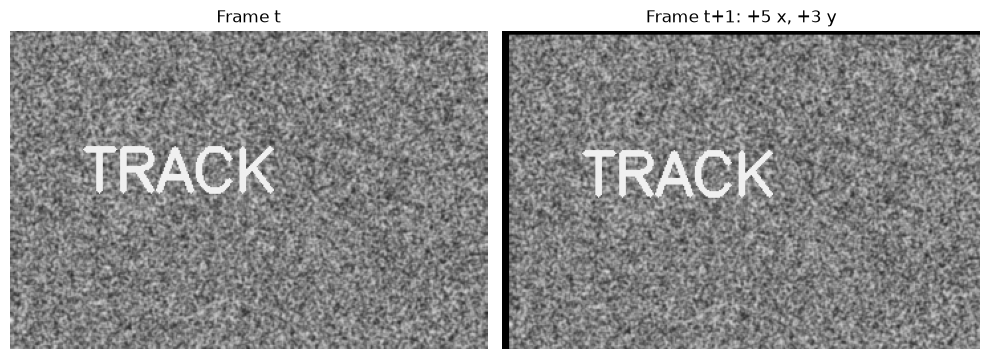

In [2]:
flow_rng = np.random.default_rng(130)
height, width = 240, 360
texture = flow_rng.integers(0, 256, (height, width), dtype=np.uint8)
frame0 = cv2.GaussianBlur(texture, (5, 5), 0.8)
cv2.putText(frame0, 'TRACK', (55, 120), cv2.FONT_HERSHEY_SIMPLEX, 1.5, 240, 3)
truth = np.array([5.0, 3.0], dtype=np.float32)
translation = np.array([[1, 0, truth[0]], [0, 1, truth[1]]], dtype=np.float32)
frame1 = cv2.warpAffine(frame0, translation, (width, height), borderMode=cv2.BORDER_CONSTANT)
show_images([frame0, frame1], ['Frame t', 'Frame t+1: +5 x, +3 y'])


Before executing the next cell, predict the sign of the x and y flow. Image y increases downward. The padded border has no valid predecessor, so validation must exclude it.


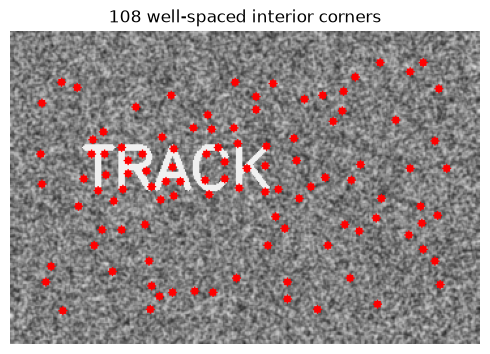

In [3]:
points0 = cv2.goodFeaturesToTrack(frame0, maxCorners=150, qualityLevel=0.03,
                                 minDistance=10, blockSize=7)
assert points0 is not None and len(points0) > 20
interior = ((points0[:, 0, 0] > 20) & (points0[:, 0, 0] < width-25) &
            (points0[:, 0, 1] > 20) & (points0[:, 0, 1] < height-25))
points0 = points0[interior]
marked = cv2.cvtColor(frame0, cv2.COLOR_GRAY2BGR)
for x, y in points0[:, 0]:
    cv2.circle(marked, (int(x), int(y)), 3, (0, 0, 255), -1)
show_images([marked], [f'{len(points0)} well-spaced interior corners'])


## Step 2 — Sparse Lucas–Kanade tracking
`calcOpticalFlowPyrLK` follows selected points through an image pyramid. Coarse levels make motion smaller; finer levels refine it. `status` tells us whether a track was found, but **does not prove it is correct**. Its `err` value is also not ground-truth endpoint error.


In [4]:
lk_parameters = dict(winSize=(21, 21), maxLevel=3,
                     criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))
points1, status, lk_error = cv2.calcOpticalFlowPyrLK(frame0, frame1, points0, None, **lk_parameters)
found = status.ravel().astype(bool)
displacements = points1[:, 0] - points0[:, 0]
endpoint_error = np.linalg.norm(displacements - truth, axis=1)
print('Found tracks:', found.sum(), '/', len(found))
print('Median measured [dx, dy]:', np.median(displacements[found], axis=0).round(3))
print('Median endpoint error (pixels):', round(float(np.median(endpoint_error[found])), 4))
assert found.sum() > 30 and np.median(endpoint_error[found]) < 0.3


Found tracks: 108 / 108
Median measured [dx, dy]: [5. 3.]
Median endpoint error (pixels): 0.0002


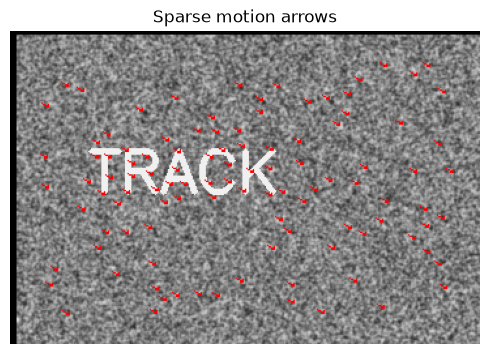

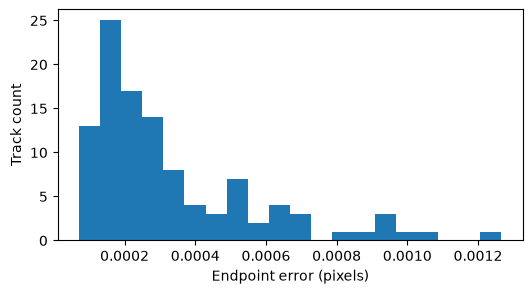

In [5]:
track_view = cv2.cvtColor(frame1, cv2.COLOR_GRAY2BGR)
for old, new in zip(points0[found, 0], points1[found, 0]):
    cv2.arrowedLine(track_view, tuple(np.round(old).astype(int)),
                   tuple(np.round(new).astype(int)), (0, 0, 255), 1, tipLength=0.35)
show_images([track_view], ['Sparse motion arrows'])
plt.figure(figsize=(6, 3))
plt.hist(endpoint_error[found], bins=20)
plt.xlabel('Endpoint error (pixels)'); plt.ylabel('Track count'); plt.show()


## Step 3 — Forward–backward checks and occlusion
Track forward, then backward. If the returned point is far from the original point, reject the track. This is a consistency check, not a guarantee: a repeated pattern can produce a consistent but incorrect match in both directions.


Accepted after occlusion: 10 / 108


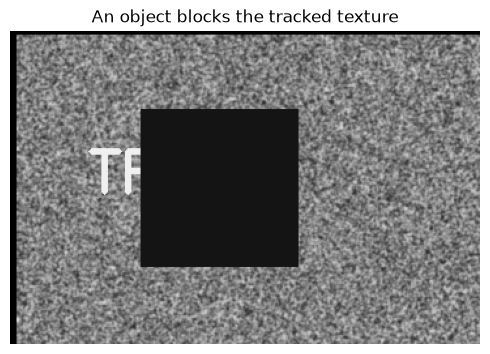

In [6]:
def track_with_consistency(previous, current, points, threshold=0.8):
    forward, s1, _ = cv2.calcOpticalFlowPyrLK(previous, current, points, None, **lk_parameters)
    if forward is None:
        return None, np.zeros(len(points), dtype=bool), np.full(len(points), np.inf)
    backward, s2, _ = cv2.calcOpticalFlowPyrLK(current, previous, forward, None, **lk_parameters)
    if backward is None:
        return forward, np.zeros(len(points), dtype=bool), np.full(len(points), np.inf)
    fb_error = np.linalg.norm(backward[:, 0] - points[:, 0], axis=1)
    inside = ((forward[:, 0, 0] >= 0) & (forward[:, 0, 0] < current.shape[1]) &
              (forward[:, 0, 1] >= 0) & (forward[:, 0, 1] < current.shape[0]))
    good = s1.ravel().astype(bool) & s2.ravel().astype(bool) & inside & (fb_error < threshold)
    return forward, good, fb_error

occluded = frame1.copy()
cv2.rectangle(occluded, (100, 60), (220, 180), 20, -1)
occluded_tracks, accepted, fb_error = track_with_consistency(frame0, occluded, points0)
print('Accepted after occlusion:', accepted.sum(), '/', len(accepted))
show_images([occluded], ['An object blocks the tracked texture'])


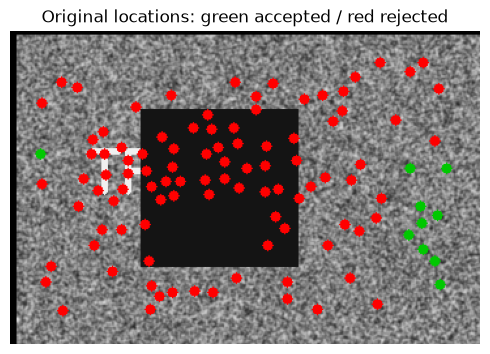

FB threshold 0.2 px -> 10 accepted
FB threshold 0.8 px -> 10 accepted
FB threshold 2.0 px -> 10 accepted


In [7]:
occlusion_view = cv2.cvtColor(occluded, cv2.COLOR_GRAY2BGR)
for point, keep in zip(points0[:, 0], accepted):
    cv2.circle(occlusion_view, tuple(np.round(point).astype(int)), 4,
               (0, 200, 0) if keep else (0, 0, 255), -1)
show_images([occlusion_view], ['Original locations: green accepted / red rejected'])
for cutoff in [0.2, 0.8, 2.0]:
    _, mask, _ = track_with_consistency(frame0, occluded, points0, cutoff)
    print(f'FB threshold {cutoff:.1f} px -> {mask.sum()} accepted')


## Step 4 — Dense Farnebäck flow
Dense flow assigns a vector to every pixel, including pixels where motion is ambiguous. Exclude borders and report a distribution of errors rather than trusting an attractive color plot. Hue below encodes direction; value encodes speed relative to this frame pair.


Dense EPE median / 90th percentile: [0.00088364 0.00137606]


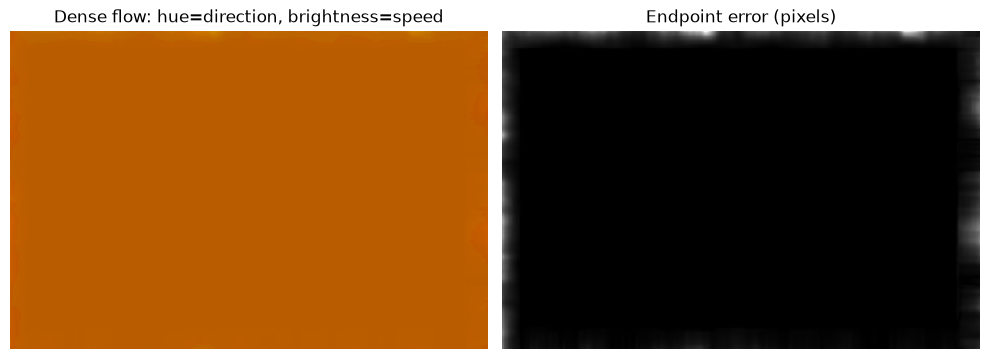

In [8]:
dense = cv2.calcOpticalFlowFarneback(frame0, frame1, None, 0.5, 3, 21, 5, 7, 1.5, 0)
assert dense.shape == (height, width, 2)
valid_region = np.zeros((height, width), dtype=bool)
valid_region[25:-25, 25:-25] = True
dense_error = np.linalg.norm(dense - truth, axis=2)
print('Dense EPE median / 90th percentile:', np.percentile(dense_error[valid_region], [50, 90]))
assert np.median(dense_error[valid_region]) < 0.5
magnitude, angle = cv2.cartToPolar(dense[..., 0], dense[..., 1])
hsv = np.zeros((height, width, 3), dtype=np.uint8)
hsv[..., 0] = (angle * 180 / np.pi / 2).astype(np.uint8)
hsv[..., 1] = 255
hsv[..., 2] = np.clip(magnitude / 8 * 255, 0, 255).astype(np.uint8)
show_images([cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR), dense_error],
            ['Dense flow: hue=direction, brightness=speed', 'Endpoint error (pixels)'])


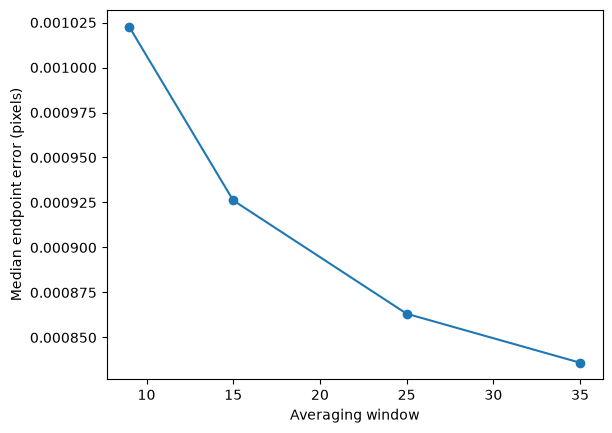

In [9]:
window_scores = []
for window in [9, 15, 25, 35]:
    estimated = cv2.calcOpticalFlowFarneback(frame0, frame1, None, 0.5, 3, window, 4, 7, 1.5, 0)
    error = np.linalg.norm(estimated - truth, axis=2)
    window_scores.append(float(np.median(error[valid_region])))
plt.plot([9, 15, 25, 35], window_scores, marker='o')
plt.xlabel('Averaging window'); plt.ylabel('Median endpoint error (pixels)'); plt.show()


A larger window gathers more evidence but can mix two objects moving differently. The optimum on this single translating plane is not a universal setting. Try a foreground rectangle that moves in the opposite direction.


## Step 5 — Multi-frame tracking and drift
Each estimate depends on the previous estimate. Errors accumulate, tracks disappear, and an application must decide when to detect fresh features. A low track count is an observable reason to reinitialize; silently pretending a lost point still exists is not.


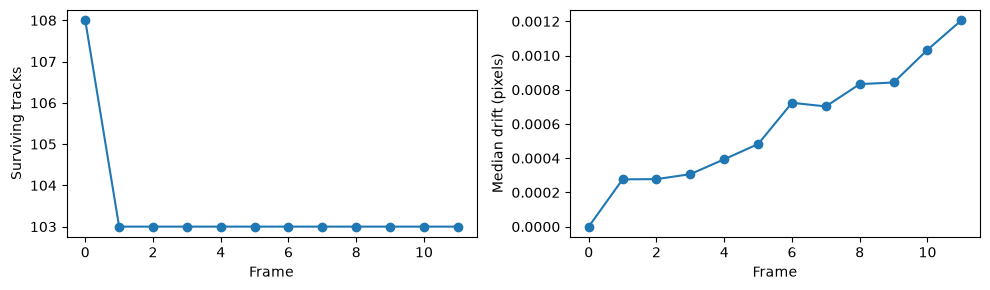

In [10]:
sequence = [cv2.warpAffine(frame0, np.float32([[1, 0, i*2], [0, 1, i]]),
                           (width, height)) for i in range(12)]
current_points = points0.copy()
identities = np.arange(len(points0))
counts, median_drift = [len(points0)], [0.0]
for index in range(1, len(sequence)):
    moved, good, _ = track_with_consistency(sequence[index-1], sequence[index], current_points)
    if moved is None or not good.any():
        print('No surviving tracks; redetect features before continuing.')
        break
    identities = identities[good]
    current_points = moved[good]
    expected = points0[identities, 0] + np.array([index*2, index])
    counts.append(len(current_points))
    median_drift.append(float(np.median(np.linalg.norm(current_points[:, 0] - expected, axis=1))))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(counts, marker='o'); axes[0].set(xlabel='Frame', ylabel='Surviving tracks')
axes[1].plot(median_drift, marker='o'); axes[1].set(xlabel='Frame', ylabel='Median drift (pixels)')
plt.tight_layout(); plt.show()


## Step 6 — Investigate an unobservable case
A completely uniform image is unchanged by a translation away from its border. No image-based method can recover the motion there. A motion estimate of zero can mean **no evidence**, rather than a stationary object.


In [11]:
flat0 = np.full_like(frame0, 128)
flat1 = cv2.warpAffine(flat0, translation, (width, height), borderMode=cv2.BORDER_REFLECT)
flat_corners = cv2.goodFeaturesToTrack(flat0, 100, 0.01, 5)
flat_flow = cv2.calcOpticalFlowFarneback(flat0, flat1, None, 0.5, 3, 21, 3, 5, 1.2, 0)
print('Detected flat-image corners:', flat_corners)
print('Median estimated flow:', np.median(flat_flow[valid_region], axis=0))
print('True translation remains:', truth, '— it cannot be inferred from these observations.')
assert np.array_equal(flat0, flat1)


Detected flat-image corners: None
Median estimated flow: [0. 0.]
True translation remains: [5. 3.] — it cannot be inferred from these observations.


### Practice before opening the solutions
1. Change the translation to `(12, -4)` and compare pyramidal LK with `maxLevel=0`.
2. Measure the percentage of surviving tracks whose true error exceeds one pixel after occlusion.
3. Create a spatial mask for texture-rich pixels, and compare dense error inside and outside it. Explain why ground-truth-free consistency is different from accuracy.

Write your prediction and result in a new Markdown cell. Keep validation regions inside the overlapping field of view.


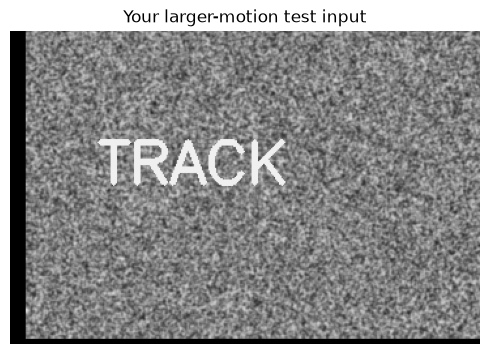

In [12]:
# Your experiment: change one parameter, rerun, and record a numerical result.
experiment_translation = (12, -4)
experiment_frame = cv2.warpAffine(frame0, np.float32([[1, 0, experiment_translation[0]],
                                                  [0, 1, experiment_translation[1]]]), (width, height))
show_images([experiment_frame], ['Your larger-motion test input'])


### Worked solutions
The exercise compares the same points under two pyramid settings, so the metric isolates that choice. Pyramids help large motions but cannot solve complete occlusion or missing texture.


In [13]:
for levels in [0, 3]:
    params = {**lk_parameters, 'maxLevel': levels}
    p, s, _ = cv2.calcOpticalFlowPyrLK(frame0, experiment_frame, points0, None, **params)
    keep = s.ravel().astype(bool)
    epe = np.linalg.norm(p[keep, 0] - points0[keep, 0] - experiment_translation, axis=1)
    print(f'Pyramid maxLevel={levels}: tracks={keep.sum()}, median EPE={np.median(epe):.3f} px')
if accepted.any():
    error = np.linalg.norm(occluded_tracks[accepted, 0] - points0[accepted, 0] - truth, axis=1)
    print('Accepted occluded-scene tracks with EPE > 1px:', f'{100*np.mean(error > 1):.1f}%')
gx = cv2.Sobel(frame0, cv2.CV_32F, 1, 0)
gy = cv2.Sobel(frame0, cv2.CV_32F, 0, 1)
energy = cv2.GaussianBlur(gx*gx + gy*gy, (11, 11), 0)
rich = energy > np.median(energy[valid_region])
for label, mask in [('more gradient energy', rich), ('less gradient energy', ~rich)]:
    print(label, ': median dense EPE=', round(float(np.median(dense_error[mask & valid_region])), 4))


Pyramid maxLevel=0: tracks=108, median EPE=12.953 px
Pyramid maxLevel=3: tracks=108, median EPE=0.000 px
Accepted occluded-scene tracks with EPE > 1px: 0.0%
more gradient energy : median dense EPE= 0.0008
less gradient energy : median dense EPE= 0.001


### Checkpoint and references
You can now distinguish tracking status, consistency, and actual error. Real scenes add changing exposure, motion blur, rolling shutter, independently moving objects, and camera motion. Test these separately before calling a tracker reliable.

- [OpenCV optical flow tutorial](https://docs.opencv.org/4.x/d4/dee/tutorial_optical_flow.html)
- [OpenCV tracking API](https://docs.opencv.org/4.x/dc/d6b/group__video__track.html)

Next: recover camera geometry and pose instead of only image motion.
